# Traffic Sign Recognition: SVM versus CNN

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare classical image features and convolutional models for road-sign classification.

**Approach:** OpenCV/HOG + SVM contrasted with a CNN.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


<div class="alert alert-success">
    <center><b>University of Ghardaia</b></center>
    <center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i></center>
</div>

------

<br><br>

<center>
    <span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Project - RM2: Recognition of traffic signs (SVM)  </span></span>
</center>
<br>
</center>

## Guerbouz Mohammed Alaa Eddine

In [38]:
import os
import cv2
import numpy as np
import pandas as pd
import xml.etree.ElementTree as ET
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

## Define Classes from datasets

In [39]:


# Class labels for the dataset
label_dict = {name: idx for idx, name in enumerate([
    'Speed limit (5km/h)', 'Speed limit (15km/h)', 'Speed limit (30km/h)', 
    'Speed limit (40km/h)', 'Speed limit (50km/h)', 'Speed limit (60km/h)', 
    'Speed limit (70km/h)', 'Speed limit (80km/h)', "Don't Go straight or left", 
    "Don't Go straight or Right", "Don't Go straight", "Don't Go Left", 
    "Don't Go Left or Right", "Don't Go Right", "Don't overtake from Left", 
    'No Uturn', 'No Car', 'No horn', 'Speed limit (40km/h)', 'Speed limit (50km/h)', 
    'Go straight or right', 'Go straight', 'Go Left', 'Go Left or right', 'Go Right', 
    'keep Left', 'keep Right', 'Roundabout mandatory', 'watch out for cars', 
    'Horn', 'Bicycles crossing', 'Uturn', 'Road Divider', 'Traffic signals', 'Danger Ahead', 
    'Zebra Crossing', 'Bicycles crossing', 'Children crossing', 'Dangerous curve to the left', 
    'Dangerous curve to the right', 'Unknown1', 'Unknown2', 'Unknown3', 'Go right or straight', 
    'Go left or straight', 'Unknown4', 'ZigZag Curve', 'Train Crossing', 'Under Construction', 
    'Unknown5', 'Fences', 'Heavy Vehicle Accidents', 'Unknown6', 'Give Way', 'No stopping', 
    'No entry', 'Unknown7', 'Unknown8'
])}
label_mapping = {
    0: 'Speed limit (5km/h)',
    1: 'Speed limit (15km/h)',
    2: 'Speed limit (30km/h)',
    3: 'Speed limit (40km/h)',
    4: 'Speed limit (50km/h)',
    5: 'Speed limit (60km/h)',
    6: 'Speed limit (70km/h)',
    7: 'Speed limit (80km/h)',
    8: "Don't Go straight or left",
    9: "Don't Go straight or Right",
    10: "Don't Go straight",
    11: "Don't Go Left",
    12: "Don't Go Left or Right",
    13: "Don't Go Right",
    14: 'Don\'t overtake from Left',
    15: 'No Uturn',
    16: 'No Car',
    17: 'No horn',
    18: 'Speed limit (40km/h)',
    19: 'Speed limit (50km/h)',
    20: 'Go straight or right',
    21: 'Go straight',
    22: 'Go Left',
    23: 'Go Left or right',
    24: 'Go Right',
    25: 'keep Left',
    26: 'keep Right',
    27: 'Roundabout mandatory',
    28: 'watch out for cars',
    29: 'Horn',
    30: 'Bicycles crossing',
    31: 'Uturn',
    32: 'Road Divider',
    33: 'Traffic signals',
    34: 'Danger Ahead',
    35: 'Zebra Crossing',
    36: 'Bicycles crossing',
    37: 'Children crossing',
    38: 'Dangerous curve to the left',
    39: 'Dangerous curve to the right',
    40: 'Unknown1',
    41: 'Unknown2',
    42: 'Unknown3',
    43: 'Go right or straight',
    44: 'Go left or straight',
    45: 'Unknown4',
    46: 'ZigZag Curve',
    47: 'Train Crossing',
    48: 'Under Construction',
    49: 'Unknown5',
    50: 'Fences',
    51: 'Heavy Vehicle Accidents',
    52: 'Unknown6',
    53: 'Give Way',
    54: 'No stopping',
    55: 'No entry',
    56: 'Unknown7',
    57: 'Unknown8'
}



## hog Function to detect edges and features

In [40]:
# Function to extract HOG features
def extract_hog_features(image, size=(64, 64)):
    return hog(cv2.resize(image, size), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')

## Load dataset 1 And dataset 2

In [41]:

# Load Dataset 1
def load_images_and_labels_from_dataset1(data_path, labels_csv):
    labels_df = pd.read_csv(labels_csv)
    label_dict_dataset1 = dict(zip(labels_df["ClassId"], labels_df["Name"]))
    X, y = [], []
    for folder in os.listdir(data_path):
        folder_path = os.path.join(data_path, folder)
        if os.path.isdir(folder_path):
            label = label_dict_dataset1.get(int(folder), "Unknown")
            for img_name in os.listdir(folder_path):
                img = cv2.imread(os.path.join(folder_path, img_name), cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    X.append(extract_hog_features(img))
                    y.append(label)
    return np.array(X), np.array(y)

# Load Dataset 2
def load_images_and_labels_from_dataset2(image_dir, annotation_dir):
    X, y = [], []
    for filename in os.listdir(annotation_dir):
        if filename.endswith('.xml'):
            tree = ET.parse(os.path.join(annotation_dir, filename))
            img = cv2.imread(os.path.join(image_dir, filename.replace('.xml', '.png')), cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            for obj in tree.getroot().findall('object'):
                class_name = obj.find('name').text.lower()
                xmin, ymin, xmax, ymax = map(int, [obj.find('bndbox').find(c).text for c in ['xmin', 'ymin', 'xmax', 'ymax']])
                cropped_img = img[ymin:ymax, xmin:xmax]
                X.append(extract_hog_features(cropped_img))
                y.append(label_dict.get(class_name, 1))
    return np.array(X), np.array(y)

# Main paths and data loading
data_path_1 = r"C:\Users\Dingue\TPRM2Dataset2\archive2\traffic_Data\DATA"
labels_csv_path = r"labels.csv"
image_dir_2 = r"C:\Users\Dingue\Desktop\TP Reasaux\RM2\archive\images"
annotation_dir_2 = r"C:\Users\Dingue\Desktop\TP Reasaux\RM2\archive\annotations"


## Combain the two datasets using numpy

In [42]:

X1, y1 = load_images_and_labels_from_dataset1(data_path_1, labels_csv_path)
X2, y2 = load_images_and_labels_from_dataset2(image_dir_2, annotation_dir_2)
X, y = np.concatenate((X1, X2)), np.concatenate((y1, y2))


## extract the train sets and tests sets and fit it to the SvmModel 

In [43]:

# Encode labels
#label_encoder = LabelEncoder()
#y = label_encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train SVM
svm = SVC(kernel='rbf', C=1.0, gamma='scale')
svm.fit(X_train, y_train)

# Evaluate model
y_pred = svm.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))



Classification Report:
                               precision    recall  f1-score   support

                           1       1.00      1.00      1.00       245
           Bicycles crossing       1.00      1.00      1.00        37
           Children crossing       0.92      1.00      0.96        12
                Danger Ahead       1.00      1.00      1.00         7
 Dangerous curve to the left       1.00      1.00      1.00         4
Dangerous curve to the right       1.00      1.00      1.00        13
                Dont Go Left       1.00      1.00      1.00        32
       Dont Go Left or Right       0.92      1.00      0.96        22
               Dont Go Right       1.00      0.80      0.89        10
            Dont Go straight       1.00      1.00      1.00        12
   Dont Go straight or Right       0.00      0.00      0.00         1
    Dont Go straight or left       1.00      1.00      1.00         2
     Dont overtake from Left       1.00      1.00      1.00      

C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Dingue\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


## Hog Function result on Images

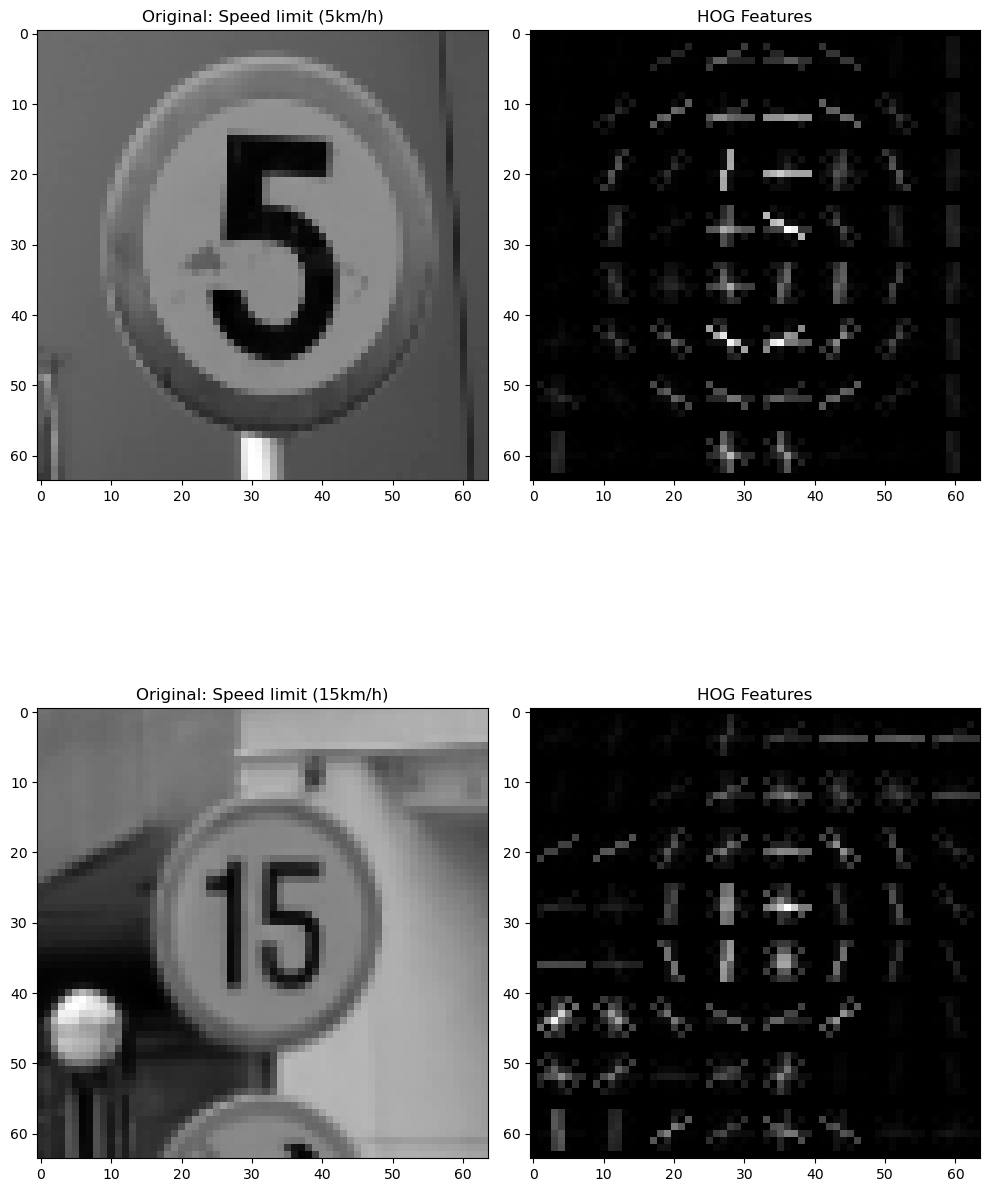

In [44]:
## Visualizing some HOG features
def visualize_hog(data_path, sample_count=2):
    sample_images = []
    sample_labels = []
    hog_features = []

    for folder in os.listdir(data_path):
        folder_path = os.path.join(data_path, folder)
        if not os.path.isdir(folder_path):
            continue

        for img_name in os.listdir(folder_path)[:1]:
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img_resized = cv2.resize(img, (64, 64))
                fd, hog_image = hog(img_resized, block_norm='L2-Hys', visualize=True)
                sample_images.append(img_resized)
                hog_features.append(hog_image)
                sample_labels.append(label_mapping.get(int(folder), "Unknown"))

    # Plot images and their HOG features
    fig, axes = plt.subplots(sample_count, 2, figsize=(10, 15))
    for i in range(sample_count):
        axes[i, 0].imshow(sample_images[i], cmap='gray')
        axes[i, 0].set_title(f"Original: {sample_labels[i]}")
        axes[i, 1].imshow(hog_features[i], cmap='gray')
        axes[i, 1].set_title("HOG Features")
    plt.tight_layout()
    plt.show()

# Visualize a few samples with their HOG features
visualize_hog(data_path_1)

## Shapes of the images in train and test 

In [45]:
print(f"X_test_images shape: {X_test.shape}, y_test_images shape: {y_test.shape}")
print(f"Unique test labels: {np.unique(y_test)}")

X_test_images shape: (1083, 1764), y_test_images shape: (1083,)
Unique test labels: ['1' 'Bicycles crossing' 'Children crossing' 'Danger Ahead'
 'Dangerous curve to the left' 'Dangerous curve to the right'
 'Dont Go Left' 'Dont Go Left or Right' 'Dont Go Right' 'Dont Go straight'
 'Dont Go straight or Right' 'Dont Go straight or left'
 'Dont overtake from Left' 'Fences' 'Give Way' 'Go Left'
 'Go Left or right' 'Go Right' 'Go left or straight'
 'Go right or straight' 'Go straight' 'Go straight or right'
 'Heavy Vehicle Accidents' 'Horn' 'No Car' 'No Uturn' 'No entry' 'No horn'
 'No stopping' 'Road Divider' 'Roundabout mandatory'
 'Speed limit (15km/h)' 'Speed limit (30km/h)' 'Speed limit (40km/h)'
 'Speed limit (50km/h)' 'Speed limit (5km/h)' 'Speed limit (60km/h)'
 'Speed limit (70km/h)' 'Traffic signals' 'Under Construction' 'Unknown1'
 'Unknown2' 'Unknown3' 'Unknown4' 'Unknown5' 'Unknown6' 'Unknown7'
 'Unknown8' 'Uturn' 'Zebra Crossing' 'ZigZag Curve' 'keep Left'
 'keep Right' 'speed

## onfusion Matrix Representation 

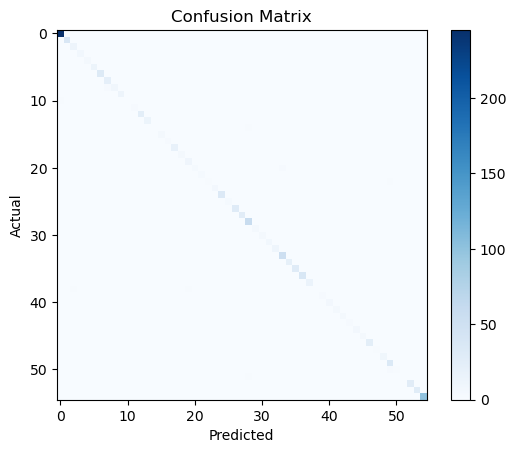

In [46]:

# Confusion Matrix Visualization
plt.imshow(confusion_matrix(y_test, y_pred), cmap="Blues", interpolation="nearest")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## Accuracy of the model

In [47]:
# Print accuracy and classification report
print("Accuracy:", np.mean(y_pred == y_test) * 100)

Accuracy: 98.89196675900277


In [48]:
# Test SVM with an image
def test_svm_with_image(svm, image_path, size=(64, 64)):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None: raise ValueError(f"Image {image_path} not found.")
    features = extract_hog_features(img, size)
    prediction = svm.predict([features / 255.0])
    return prediction

# Test a sample image
test_image_path = r"002_1_0011_1_j.png"
try:
    predicted_label = test_svm_with_image(svm, test_image_path, size=(64, 64))
    print(f"Predicted label: {predicted_label}")
except ValueError as e:
    print(f"Error: {e}")


Predicted label: ['1']


## Test Image Nad the prediction of it in the model 

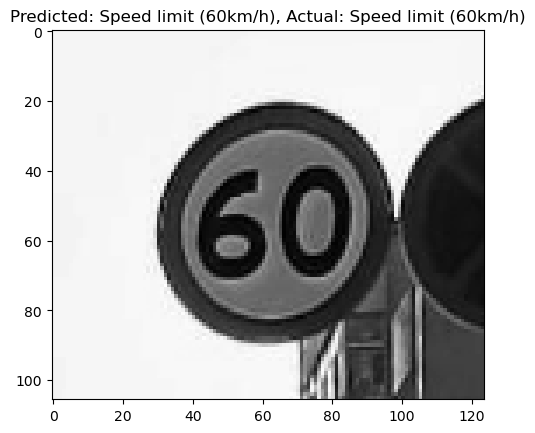

In [49]:
# Display a few test images with predicted and actual labels
import matplotlib.pyplot as plt

test_path= r"C:\Users\Dingue\TPRM2Dataset2\archive2\traffic_Data\TEST"
img_path = os.path.join(test_path, os.listdir(test_path)[240])
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
plt.imshow(img, cmap='gray')
plt.title(f"Predicted: {y_pred[240]}, Actual: {y_test[240]}")
plt.show()
